
BEST (rw_symmetry):
interval                 2500ms
k                             2
R_Qp_trigger_rate      0.897877
B_Q1-p_trigger_rate         0.0
J                      0.897877


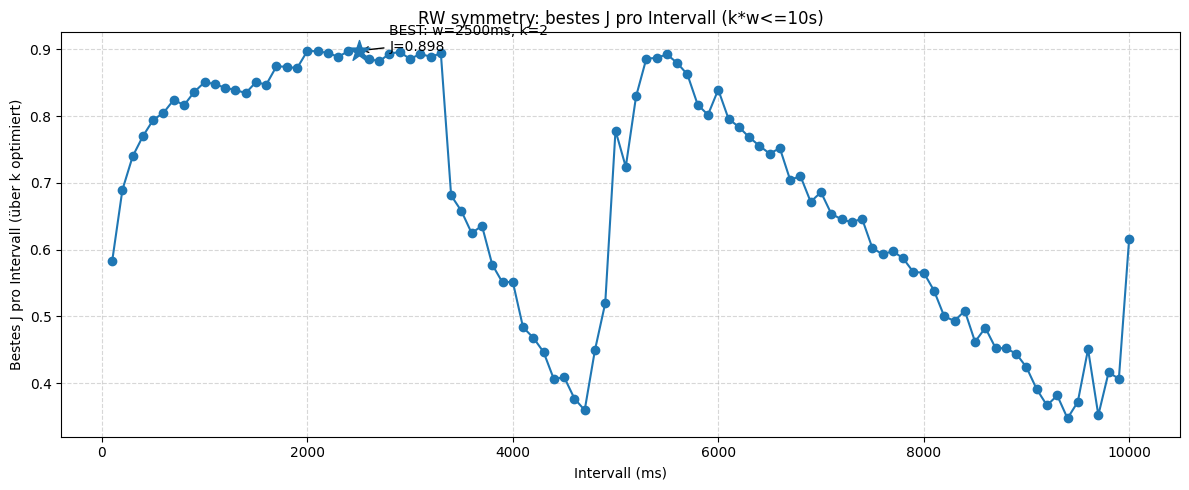


BEST (entropy_mean):
interval                 2500ms
k                             3
R_Qp_trigger_rate      0.940636
B_Q1-p_trigger_rate     0.00315
J                      0.937486


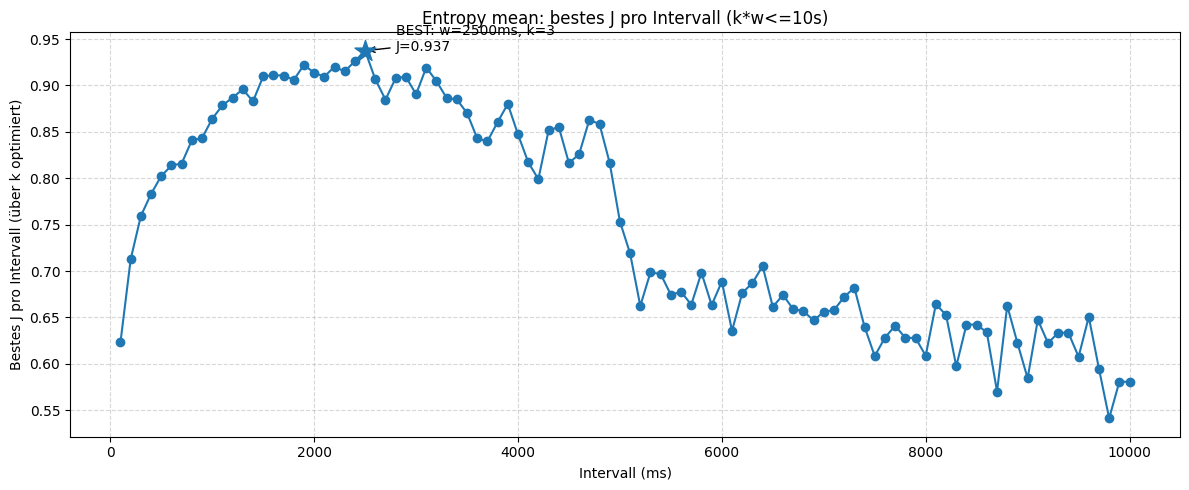


CSV gespeichert: grid_eval_combined.csv


In [ ]:
from __future__ import annotations

from pathlib import Path
from typing import Callable

import numpy as np
import pandas as pd

# Optional (nur wenn MAKE_PLOTS=True)
import matplotlib.pyplot as plt


# ==============================================================================
# PATHS
# ==============================================================================
BASE_RANSOM_NO_ENTROPY = Path("../logs/ransomware/monitor_logs_ransomware_no_entropy")
RANSOM_LOGS_NO_ENTROPY = sorted(BASE_RANSOM_NO_ENTROPY.glob("run*.csv"))

BASE_BENIGN_NO_ENTROPY = Path("../logs/benig/benig_no_entropy")
BENIGN_LOGS_NO_ENTROPY = sorted(BASE_BENIGN_NO_ENTROPY.glob("run*.csv"))

BASE_RANSOM_WITH_ENTROPY = Path("../logs/ransomware/monitor_logs_ransomware_with_entropy")
RANSOM_LOGS_WITH_ENTROPY = sorted(BASE_RANSOM_WITH_ENTROPY.glob("run*.csv"))

BASE_BENIGN_WITH_ENTROPY = Path("../logs/benig/benign_entropy")
BENIGN_LOGS_WITH_ENTROPY = sorted(BASE_BENIGN_WITH_ENTROPY.glob("run*.csv"))


# ==============================================================================
# CONFIG
# ==============================================================================
TIME_COL = "timestamp"
OP_COL = "op"
BYTES_COL = "bytes"
ENTROPY_COL = "entropy"

RW_SYMMETRY_THRESHOLD = 0.337480
ENTROPY_THRESHOLD = 7.5

DMAX_SECONDS = 10.0
INTERVALS = [f"{ms}ms" for ms in range(100, 10_000 + 1, 100)]

P_QUANTILE_WORST_RANSOMWARE = 0.10
J_EPS = 1e-9
MAKE_PLOTS = True


# ==============================================================================
# TYPES
# ==============================================================================
SuspectFn = Callable[[pd.DataFrame], pd.Series]
# callback(features_df) -> pd.Series[bool] (Index = window timestamps)


# ==============================================================================
# LOAD
# ==============================================================================
def load_run_csv(path: Path, label: str) -> pd.DataFrame:
    df = pd.read_csv(path)

    if TIME_COL not in df.columns:
        raise ValueError(f"[{label}] missing '{TIME_COL}'. Columns: {list(df.columns)}")

    # ISO timestamps with 'Z' + nanoseconds are fine with pandas; use utc for safety.
    df[TIME_COL] = pd.to_datetime(df[TIME_COL], utc=True, errors="raise")
    df = df.sort_values(TIME_COL).set_index(TIME_COL)
    df["label"] = label

    if OP_COL in df.columns:
        df[OP_COL] = df[OP_COL].astype(str)

    if BYTES_COL in df.columns:
        df[BYTES_COL] = pd.to_numeric(df[BYTES_COL], errors="coerce")

    if ENTROPY_COL in df.columns:
        df[ENTROPY_COL] = pd.to_numeric(df[ENTROPY_COL], errors="coerce")

    return df


# ==============================================================================
# WINDOW FEATURES
# ==============================================================================
def build_window_features(df: pd.DataFrame, interval: str) -> pd.DataFrame:
    """
    Pro Fenster (interval) werden Features aggregiert.
    Active-Regel (wie im Konzept):
      - wenn reads/writes vorhanden: active := (reads_sum + writes_sum > 0)
      - sonst: active := (entropy_count > 0) falls entropy vorhanden
      - sonst: active := (event_count > 0)
    """
    # Grundgerüst: Fensterindex erzeugen über count
    feats = df.resample(interval, origin="start").size().to_frame("event_count")

    # Reads/Writes counts (falls op da ist)
    if OP_COL in df.columns:
        op = df[OP_COL].astype(str)
        reads = op.str.contains("read", case=False, na=False).astype(int)
        writes = op.str.contains("write", case=False, na=False).astype(int)

        rw = pd.DataFrame({"reads": reads, "writes": writes}, index=df.index).resample(
            interval, origin="start"
        ).sum()
        feats["reads_sum"] = rw["reads"].astype(int)
        feats["writes_sum"] = rw["writes"].astype(int)
    else:
        feats["reads_sum"] = np.nan
        feats["writes_sum"] = np.nan

    # Bytes sum (optional)
    if BYTES_COL in df.columns:
        feats["bytes_sum"] = df[BYTES_COL].resample(interval, origin="start").sum(min_count=1)
    else:
        feats["bytes_sum"] = np.nan

    # Entropy aggregates (optional)
    if ENTROPY_COL in df.columns:
        ent = df[ENTROPY_COL].resample(interval, origin="start").agg(["mean", "count"])
        feats["entropy_mean"] = ent["mean"]
        feats["entropy_count"] = ent["count"].astype(int)
    else:
        feats["entropy_mean"] = np.nan
        feats["entropy_count"] = 0

    # Active-Regel
    if "reads_sum" in feats.columns and "writes_sum" in feats.columns and feats["reads_sum"].notna().any():
        denom = feats["reads_sum"].astype(float) + feats["writes_sum"].astype(float)
        feats["active"] = denom > 0
    elif ENTROPY_COL in df.columns:
        feats["active"] = feats["entropy_count"].astype(int) > 0
    else:
        feats["active"] = feats["event_count"].astype(int) > 0

    return feats


# ==============================================================================
# CALLBACKS (SUSPECT)
# ==============================================================================
def make_entropy_callback(thr: float = ENTROPY_THRESHOLD) -> SuspectFn:
    """
    suspect := (entropy_mean >= thr) AND active
    """
    def _fn(features: pd.DataFrame) -> pd.Series:
        if "entropy_mean" not in features.columns:
            raise ValueError("Entropy callback: 'entropy_mean' missing in features.")
        metric = pd.to_numeric(features["entropy_mean"], errors="coerce")
        return (metric >= float(thr)) & features["active"].astype(bool)

    return _fn


def make_rw_symmetry_callback(theta: float = RW_SYMMETRY_THRESHOLD) -> SuspectFn:
    """
    d_i = |r_i - w_i| / (r_i + w_i) (nur in active Fenstern)
    suspect := (d_i <= theta) AND active
    """
    def _fn(features: pd.DataFrame) -> pd.Series:
        if "reads_sum" not in features.columns or "writes_sum" not in features.columns:
            raise ValueError("RW callback: 'reads_sum'/'writes_sum' missing in features.")

        r = pd.to_numeric(features["reads_sum"], errors="coerce").fillna(0.0)
        w = pd.to_numeric(features["writes_sum"], errors="coerce").fillna(0.0)
        active = features["active"].astype(bool)

        denom = r + w
        d = pd.Series(np.nan, index=features.index, dtype=float)

        mask = active & (denom > 0)
        d.loc[mask] = (r.loc[mask] - w.loc[mask]).abs() / denom.loc[mask]

        return (d <= float(theta)) & active

    return _fn


# ==============================================================================
# TRIGGER RATE (k consecutive suspect inside active segments)
# ==============================================================================
def trigger_rate_from_segments(active: np.ndarray, suspect: np.ndarray, k: int) -> float:
    triggers_total = 0
    possible_total = 0

    n = len(active)
    i = 0
    while i < n:
        if not active[i]:
            i += 1
            continue

        j = i
        while j < n and active[j]:
            j += 1

        seg = suspect[i:j].astype(np.int32)
        L = seg.size

        if L >= k:
            possible_total += (L - k + 1)
            sums = np.convolve(seg, np.ones(k, dtype=np.int32), mode="valid")
            triggers_total += int(np.sum(sums == k))

        i = j

    if possible_total == 0:
        return np.nan
    return triggers_total / possible_total


def nan_quantile(values: list[float], q: float) -> float:
    arr = np.asarray(values, dtype=float)
    arr = arr[~np.isnan(arr)]
    if arr.size == 0:
        return np.nan
    return float(np.quantile(arr, q))


# ==============================================================================
# GRID EVALUATION
# ==============================================================================
def evaluate_grid_quantile_triggerrate(
    experiment_name: str,
    ransom_dfs: list[pd.DataFrame],
    benign_dfs: list[pd.DataFrame],
    suspect_fn: SuspectFn,
) -> pd.DataFrame:
    rows: list[dict] = []

    for interval in INTERVALS:
        w_s = pd.to_timedelta(interval).total_seconds()
        if w_s <= 0:
            continue

        kmax = max(1, int(np.floor(DMAX_SECONDS / w_s)))

        # Precompute active/suspect arrays per run for this interval
        r_ws: list[tuple[np.ndarray, np.ndarray]] = []
        for df in ransom_dfs:
            feats = build_window_features(df, interval)
            s = suspect_fn(feats).astype(bool).to_numpy()
            a = feats["active"].astype(bool).to_numpy()
            s = s & a
            r_ws.append((a, s))

        b_ws: list[tuple[np.ndarray, np.ndarray]] = []
        for df in benign_dfs:
            feats = build_window_features(df, interval)
            s = suspect_fn(feats).astype(bool).to_numpy()
            a = feats["active"].astype(bool).to_numpy()
            s = s & a
            b_ws.append((a, s))

        for k in range(1, kmax + 1):
            r_rates = [trigger_rate_from_segments(a, s, k) for (a, s) in r_ws]
            b_rates = [trigger_rate_from_segments(a, s, k) for (a, s) in b_ws]

            p = P_QUANTILE_WORST_RANSOMWARE
            R = nan_quantile(r_rates, p)
            B = nan_quantile(b_rates, 1.0 - p)
            J = (R - B) if (not np.isnan(R) and not np.isnan(B)) else np.nan

            rows.append({
                "experiment": experiment_name,
                "interval": interval,
                "interval_ms": int(w_s * 1000),
                "k": k,
                "kmax_for_interval": kmax,
                "R_Qp_trigger_rate": R,
                "B_Q1-p_trigger_rate": B,
                "J": J,
                "p_quantile": p,
            })

    return pd.DataFrame(rows)


def pick_best(eval_df: pd.DataFrame) -> pd.Series | None:
    tmp = eval_df.dropna(subset=["J"]).copy()
    if tmp.empty:
        return None
    j_max = float(tmp["J"].max())
    cand = tmp[tmp["J"] >= (j_max - J_EPS)].copy()
    cand = cand.sort_values(["interval_ms", "k"], ascending=[True, True])
    return cand.iloc[0]


def best_per_interval(eval_df: pd.DataFrame) -> pd.DataFrame:
    tmp = eval_df.dropna(subset=["J"]).copy()
    if tmp.empty:
        return tmp
    tmp = tmp.sort_values(["interval_ms", "J", "k"], ascending=[True, False, True])
    return tmp.groupby("interval_ms", as_index=False).first()


def plot_results(eval_df: pd.DataFrame, best: pd.Series, title: str):
    best_w = int(best["interval_ms"])
    best_k = int(best["k"])
    best_J = float(best["J"])

    best_w_df = best_per_interval(eval_df)

    plt.figure(figsize=(12, 5))
    plt.plot(best_w_df["interval_ms"], best_w_df["J"], marker="o")
    plt.scatter([best_w], [best_J], marker="*", s=250, zorder=5)
    plt.annotate(
        f"BEST: w={best_w}ms, k={best_k}\nJ={best_J:.3f}",
        xy=(best_w, best_J),
        xytext=(best_w + 300, best_J),
        arrowprops=dict(arrowstyle="->"),
    )
    plt.xlabel("Intervall (ms)")
    plt.ylabel("Bestes J pro Intervall (über k optimiert)")
    plt.title(title)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# ==============================================================================
# MAIN
# ==============================================================================
def main():
    # ---------------- RW / NO ENTROPY ----------------
    if RANSOM_LOGS_NO_ENTROPY and BENIGN_LOGS_NO_ENTROPY:
        ransom_rw = [load_run_csv(p, f"R_RW_{p.stem}") for p in RANSOM_LOGS_NO_ENTROPY]
        benign_rw = [load_run_csv(p, f"B_RW_{p.stem}") for p in BENIGN_LOGS_NO_ENTROPY]

        rw_cb = make_rw_symmetry_callback(RW_SYMMETRY_THRESHOLD)

        eval_rw = evaluate_grid_quantile_triggerrate(
            experiment_name="rw_symmetry",
            ransom_dfs=ransom_rw,
            benign_dfs=benign_rw,
            suspect_fn=rw_cb,
        )
        eval_rw.to_csv("grid_eval_rw_symmetry.csv", index=False)

        best_rw = pick_best(eval_rw)
        print("\nBEST (rw_symmetry):")
        if best_rw is None:
            print("  no valid J (check data / active windows / columns).")
        else:
            print(best_rw[["interval", "k", "R_Qp_trigger_rate", "B_Q1-p_trigger_rate", "J"]].to_string())

        if MAKE_PLOTS and best_rw is not None:
            plot_results(eval_rw, best_rw, title="RW symmetry: bestes J pro Intervall (k*w<=10s)")
    else:
        print("Skip RW(no entropy): logs not found. Check paths.")

    # ---------------- ENTROPY / WITH ENTROPY ----------------
    if RANSOM_LOGS_WITH_ENTROPY and BENIGN_LOGS_WITH_ENTROPY:
        ransom_ent = [load_run_csv(p, f"R_ENT_{p.stem}") for p in RANSOM_LOGS_WITH_ENTROPY]
        benign_ent = [load_run_csv(p, f"B_ENT_{p.stem}") for p in BENIGN_LOGS_WITH_ENTROPY]

        ent_cb = make_entropy_callback(ENTROPY_THRESHOLD)

        eval_ent = evaluate_grid_quantile_triggerrate(
            experiment_name="entropy_mean",
            ransom_dfs=ransom_ent,
            benign_dfs=benign_ent,
            suspect_fn=ent_cb,
        )
        eval_ent.to_csv("grid_eval_entropy_mean.csv", index=False)

        best_ent = pick_best(eval_ent)
        print("\nBEST (entropy_mean):")
        if best_ent is None:
            print("  no valid J (check data / active windows / entropy column).")
        else:
            print(best_ent[["interval", "k", "R_Qp_trigger_rate", "B_Q1-p_trigger_rate", "J"]].to_string())

        if MAKE_PLOTS and best_ent is not None:
            plot_results(eval_ent, best_ent, title="Entropy mean: bestes J pro Intervall (k*w<=10s)")
    else:
        print("Skip Entropy(with entropy): logs not found. Check paths.")

    # ---------------- Combined (optional) ----------------
    files = []
    if Path("grid_eval_rw_symmetry.csv").exists():
        files.append(pd.read_csv("  grid_eval_rw_symmetry.csv"))
    if Path("grid_eval_entropy_mean.csv").exists():
        files.append(pd.read_csv("grid_eval_entropy_mean.csv"))
    if files:
        combined = pd.concat(files, ignore_index=True)
        combined.to_csv("grid_eval_combined.csv", index=False)
        print("\nCSV gespeichert: grid_eval_combined.csv")


if __name__ == "__main__":
    main()